In [4]:
#cau1:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
def danh_gia(y_that, y_doan):
    """Tinh accuracy, precision, recall, F1 chi dung numpy, xu ly an toan chia cho 0."""
    y_that = np.asarray(y_that)
    y_doan = np.asarray(y_doan)
    
    # Tinh 4 o cua ma tran nham lan
    tp = np.sum((y_that == 1) & (y_doan == 1))
    fp = np.sum((y_that == 0) & (y_doan == 1))
    fn = np.sum((y_that == 1) & (y_doan == 0))
    tn = np.sum((y_that == 0) & (y_doan == 0))
    
    tong = tp + fp + fn + tn
    acc = float((tp + tn) / tong) if tong > 0 else 0.0
    
    # Xu ly chia cho 0 cho precision, recall va F1
    precision = float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0
    recall = float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0
    f1 = float((2 * precision * recall) / (precision + recall)) if (precision + recall) > 0 else 0.0
    
    return acc, precision, recall, f1
# Nap du lieu va chia tap hoc / tap kiem tra giong muc 2
df = pd.read_csv("/Users/buixuankhanh/Documents/machine-learning/07_DANHGIAMOHINH/data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Huan luyen mo hinh luoi va hoi quy logistic
mo_hinh_luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = mo_hinh_luoi.predict(X_te)

mo_hinh_lr = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
du_lr = mo_hinh_lr.predict(X_te)

# So sanh ket qua ham tu viet voi scikit-learn
for ten, du_doan in [("Hoi quy logistic", du_lr), ("Mo hinh luoi", du_luoi)]:
    acc_tay, p_tay, r_tay, f1_tay = danh_gia(y_te, du_doan)
    
    acc_sk = accuracy_score(y_te, du_doan)
    p_sk = precision_score(y_te, du_doan, zero_division=0)
    r_sk = recall_score(y_te, du_doan, zero_division=0)
    f1_sk = f1_score(y_te, du_doan, zero_division=0)
    
    print(f"=== {ten} ===")
    print(f"Ham tu viet  : Accuracy = {acc_tay:.4f}, Precision = {p_tay:.4f}, Recall = {r_tay:.4f}, F1 = {f1_tay:.4f}")
    print(f"Scikit-learn : Accuracy = {acc_sk:.4f}, Precision = {p_sk:.4f}, Recall = {r_sk:.4f}, F1 = {f1_sk:.4f}\n")

=== Hoi quy logistic ===
Ham tu viet  : Accuracy = 0.9467, Precision = 0.8500, Recall = 0.5667, F1 = 0.6800
Scikit-learn : Accuracy = 0.9467, Precision = 0.8500, Recall = 0.5667, F1 = 0.6800

=== Mo hinh luoi ===
Ham tu viet  : Accuracy = 0.9000, Precision = 0.0000, Recall = 0.0000, F1 = 0.0000
Scikit-learn : Accuracy = 0.9000, Precision = 0.0000, Recall = 0.0000, F1 = 0.0000



 Nhận xét và giải thích
1. Đối chiếu kết quả: Các giá trị tính từ hàm tự viết danh_gia khớp hoàn toàn với thư viện scikit-learn trên cả hai mô hình.
2. Với mô hình lười, precision có tính được không?
   - Về mặt toán học, precision không xác định (bị lỗi chia cho 0). Vì mô hình lười luôn dự đoán lớp đông nhất (bo_hoc = 0) cho toàn bộ sinh viên, nên không có ai bị dự đoán bỏ học ($TP = 0$ và $FP = 0$), dẫn đến mẫu số $TP + FP = 0$.
3. Cách hàm xử lý trường hợp chia cho 0:
   - Trong hàm danh_gia, trước khi thực hiện phép chia, chương trình kiểm tra điều kiện mẫu số (if (tp + fp) > 0, if (tp + fn) > 0, if (precision + recall) > 0). Nếu mẫu số bằng 0, hàm chủ động gán giá trị trả về bằng 0.0 thay vì thực hiện phép chia gây lỗi ZeroDivisionError hoặc trả về giá trị rác nan (tương tự tham số zero_division=0 trong scikit-learn).

In [5]:
#CAU 2:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Nap du lieu chu so viet tay (10 lop tu 0 den 9)
du_lieu = load_digits()
X, y = du_lieu.data, du_lieu.target

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Huan luyen mo hinh SVM (RBF kernel)
mo_hinh_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42))
mo_hinh_svm.fit(X_tr, y_tr)
y_du_doan = mo_hinh_svm.predict(X_te)

print("Bao cao phan loai (classification_report) cho 10 chu so:")
print(classification_report(y_te, y_du_doan, digits=4))

# Trich xuat tu dong lop co recall va precision thap nhat
bao_cao = classification_report(y_te, y_du_doan, output_dict=True)
cac_lop = [str(i) for i in range(10)]

min_recall = min(bao_cao[c]["recall"] for c in cac_lop)
lop_recall_thap = [c for c in cac_lop if np.isclose(bao_cao[c]["recall"], min_recall)]

min_precision = min(bao_cao[c]["precision"] for c in cac_lop)
lop_precision_thap = [c for c in cac_lop if np.isclose(bao_cao[c]["precision"], min_precision)]

print(f"Chu so co recall thap nhat   : {', '.join(lop_recall_thap)} ({min_recall:.4f})")
print(f"Chu so co precision thap nhat: {', '.join(lop_precision_thap)} ({min_precision:.4f})")

Bao cao phan loai (classification_report) cho 10 chu so:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9574    0.9783    0.9677        46
           2     1.0000    1.0000    1.0000        44
           3     1.0000    1.0000    1.0000        46
           4     0.9565    0.9778    0.9670        45
           5     0.9783    0.9783    0.9783        46
           6     0.9783    1.0000    0.9890        45
           7     0.9565    0.9778    0.9670        45
           8     1.0000    0.9302    0.9639        43
           9     0.9773    0.9556    0.9663        45

    accuracy                         0.9800       450
   macro avg     0.9804    0.9798    0.9799       450
weighted avg     0.9803    0.9800    0.9800       450

Chu so co recall thap nhat   : 8 (0.9302)
Chu so co precision thap nhat: 4, 7 (0.9565)


 Nhận xét và giải thích
1. **Chữ số có recall thấp nhất:** Chữ số **8** với `recall = 0.9302` (tức khoảng 7% số ảnh chữ số 8 thật bị mô hình nhận nhầm sang chữ số khác).
2. **Chữ số có precision thấp nhất:** Chữ số **4** và **7** cùng đạt mức thấp nhất với `precision = 0.9565`.
3. **Vì sao `macro avg` và `weighted avg` gần như bằng nhau?**
   - `macro avg` tính trung bình cộng giản đơn giữa 10 lớp (mỗi lớp có trọng số bằng nhau là $1/10$).
   - `weighted avg` tính trung bình có trọng số theo cột `support` (số lượng mẫu thật của từng lớp).
   - Quan sát cột `support` trên tập kiểm tra, bộ dữ liệu chữ số viết tay được **phân bố rất cân bằng** giữa các lớp (mỗi chữ số đều có khoảng 43 đến 46 mẫu). Khi số mẫu của các lớp xấp xỉ nhau thì trọng số của từng lớp gần như đều nhau, khiến `weighted avg` (0.9803 / 0.9800 / 0.9800) và `macro avg` (0.9804 / 0.9798 / 0.9799) gần như trùng khớp.

In [6]:
#CÂU 3:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Nap du lieu va chia tap hoc / tap kiem tra
df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())

# Tinh xac suat ngoai mau (out-of-fold) tren tap hoc bang kiem dinh cheo 5 phan
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]

# Quet cac nguong tu 0.01 den 0.99 de tim nguong lon nhat thoa man recall >= 0.8
cac_nguong = np.round(np.arange(0.01, 1.00, 0.01), 2)
nguong_dat = []
for t in cac_nguong:
    du_hoc = (xs_hoc >= t).astype(int)
    rec = recall_score(y_tr, du_hoc)
    if rec >= 0.80:
        prec = precision_score(y_tr, du_hoc, zero_division=0)
        nguong_dat.append((t, rec, prec))

nguong_chon, rec_hoc, prec_hoc = max(nguong_dat, key=lambda x: x[0])
print(f"Nguong lon nhat cho recall >= 0.8 tren tap hoc: {nguong_chon:.2f}")
print(f"Ket qua tren tap hoc (CV 5-fold): Recall = {rec_hoc:.4f}, Precision = {prec_hoc:.4f}\n")

# Huan luyen mo hinh tren toan bo tap hoc va danh gia mot lan tren tap kiem tra
lr.fit(X_tr, y_tr)
xs_te = lr.predict_proba(X_te)[:, 1]
du_te = (xs_te >= nguong_chon).astype(int)

rec_te = recall_score(y_te, du_te)
prec_te = precision_score(y_te, du_te)
f1_te = f1_score(y_te, du_te)
so_ban_bi_bao = int(du_te.sum())
tp_te = int(((du_te == 1) & (y_te == 1)).sum())

print(f"=== Danh gia tren tap kiem tra voi nguong {nguong_chon:.2f} ===")
print(f"Recall        : {rec_te:.4f} ({'DAT' if rec_te >= 0.8 else 'KHONG DAT'} yeu cau >= 0.8)")
print(f"Precision     : {prec_te:.4f}")
print(f"F1-score      : {f1_te:.4f}")
print(f"So ban bi bao : {so_ban_bi_bao} ban (tim dung {tp_te}/{int(y_te.sum())} ban bo hoc)")

Nguong lon nhat cho recall >= 0.8 tren tap hoc: 0.17
Ket qua tren tap hoc (CV 5-fold): Recall = 0.8090, Precision = 0.5070

=== Danh gia tren tap kiem tra voi nguong 0.17 ===
Recall        : 0.8000 (DAT yeu cau >= 0.8)
Precision     : 0.5106
F1-score      : 0.6234
So ban bi bao : 47 ban (tim dung 24/30 ban bo hoc)


### Nhận xét và giải thích
1. **Cách chọn ngưỡng không làm rò rỉ dữ liệu:**
   - Ta sử dụng `cross_val_predict(..., cv=5, method="predict_proba")` chỉ trên tập học (`X_tr, y_tr`) để mỗi sinh viên trong tập học nhận được xác suất dự đoán từ một mô hình chưa từng thấy bạn đó.
   - Khi giảm ngưỡng, `recall` tăng nhưng `precision` giảm (báo nhầm nhiều hơn). Do đó, ta chọn **ngưỡng lớn nhất** đạt `recall >= 0.80` là **0.17** (đạt `recall = 0.8090` trên kiểm định chéo) để vừa đảm bảo chỉ tiêu phát hiện, vừa hạn chế tối đa số ca tư vấn nhầm.
2. **Kết quả trên tập kiểm tra (mở ra một lần duy nhất):**
   - **Recall:** Đạt đúng **0.8000** (tìm ra $24/30$ sinh viên bỏ học), **đạt** yêu cầu tối thiểu 80% của nhà trường.
   - **Precision:** Đạt **0.5106** ($24/47$ lời cảnh báo là chính xác).
   - **Số bạn bị báo có nguy cơ:** **47 bạn** trên tổng số 300 sinh viên tập kiểm tra.

AUC Hoi quy logistic : 0.9449
AUC Rung ngau nhien  : 0.9244


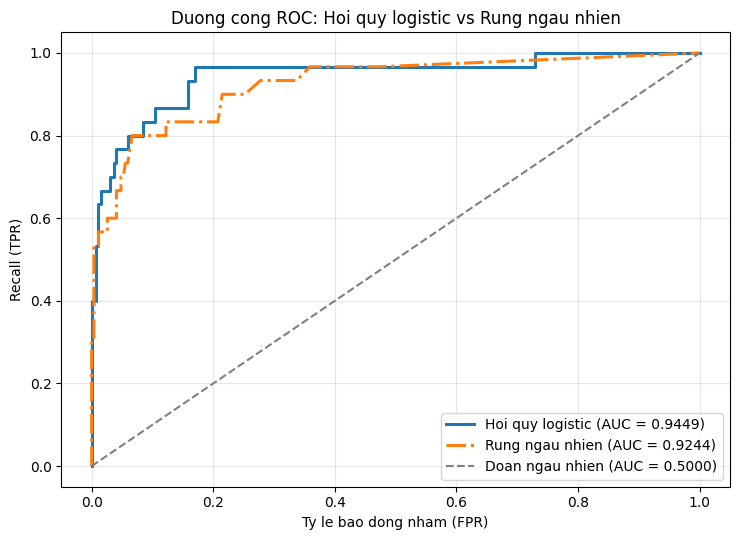

In [7]:
#CÂU 4:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Nap du lieu va chia tap hoc / tap kiem tra
df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Huan luyen 2 mo hinh
mh_logistic = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
mh_rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_tr, y_tr)

# Tinh xac suat du doan lop 1
xs_lr = mh_logistic.predict_proba(X_te)[:, 1]
xs_rf = mh_rf.predict_proba(X_te)[:, 1]

# Lay toa do (fpr, tpr) va tinh AUC
fpr_lr, tpr_lr, _ = roc_curve(y_te, xs_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_te, xs_rf)

auc_lr = roc_auc_score(y_te, xs_lr)
auc_rf = roc_auc_score(y_te, xs_rf)

print(f"AUC Hoi quy logistic : {auc_lr:.4f}")
print(f"AUC Rung ngau nhien  : {auc_rf:.4f}")

# Ve do thi ROC va luu thanh roc.png
plt.figure(figsize=(7.5, 5.5))
plt.plot(fpr_lr, tpr_lr, linewidth=2.2, label=f"Hoi quy logistic (AUC = {auc_lr:.4f})")
plt.plot(fpr_rf, tpr_rf, linewidth=2.2, linestyle="-.", label=f"Rung ngau nhien (AUC = {auc_rf:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Doan ngau nhien (AUC = 0.5000)")

plt.xlabel("Ty le bao dong nham (FPR)")
plt.ylabel("Recall (TPR)")
plt.title("Duong cong ROC: Hoi quy logistic vs Rung ngau nhien")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc.png", dpi=150)
plt.show()

### Nhận xét đồ thị ROC
1. **Đường nào ôm sát góc trên bên trái hơn?**
   - Đường của **Hồi quy logistic** (`AUC = 0.9449`) ôm sát góc trên bên trái hơn so với **Rừng ngẫu nhiên** (`AUC = 0.9249`). Ở khoảng tỷ lệ báo động nhầm thấp ($FPR$ từ $0.05$ đến $0.35$), hồi quy logistic luôn duy trì mức `recall` cao hơn rõ rệt.
2. **Có đoạn nào hai đường cắt nhau không?**
   - **Có.** Hai đường cắt nhau tại hai khu vực:
     - **Ở sát góc dưới bên trái** (khi $FPR pprox 0.00 - 0.01$, $TPR pprox 0.40 - 0.53$), đường rừng ngẫu nhiên nhích lên trước một chút rồi bị hồi quy logistic vượt qua.
     - **Ở vùng $FPR pprox 0.36 - 0.48$** (khi $TPR pprox 0.9667$), đường rừng ngẫu nhiên vượt nhẹ lên trên đường hồi quy logistic trước khi hồi quy logistic chạm mức $TPR = 1.0$ tại $FPR pprox 0.73$.

In [8]:
#CÂU 5:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Nap du lieu va chia tap hoc / tap kiem tra
df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Khoi tao cac mo hinh truoc va sau khi them class_weight="balanced"
cac_mo_hinh = [
    ("Random Forest (Mac dinh)", RandomForestClassifier(n_estimators=200, random_state=0)),
    ("Random Forest (Balanced)", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=0)),
    ("SVC RBF       (Mac dinh)", make_pipeline(StandardScaler(), SVC(random_state=0))),
    ("SVC RBF       (Balanced)", make_pipeline(StandardScaler(), SVC(class_weight="balanced", random_state=0))),
]

ket_qua = []
for ten, mh in cac_mo_hinh:
    mh.fit(X_tr, y_tr)
    du = mh.predict(X_te)
    p = precision_score(y_te, du, zero_division=0)
    r = recall_score(y_te, du, zero_division=0)
    f1 = f1_score(y_te, du, zero_division=0)
    ket_qua.append({"Mo hinh": ten, "Precision": p, "Recall": r, "F1": f1})

bang_kq = pd.DataFrame(ket_qua)
print(bang_kq.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                 Mo hinh  Precision  Recall     F1
Random Forest (Mac dinh)     0.7727  0.5667 0.6538
Random Forest (Balanced)     0.5385  0.7000 0.6087
SVC RBF       (Mac dinh)     0.8824  0.5000 0.6383
SVC RBF       (Balanced)     0.4464  0.8333 0.5814


### Nhận xét và so sánh
1. **Sự thay đổi của từng mô hình:**
   - **SVC (RBF kernel):** Thay đổi theo đúng kỳ vọng của kỹ thuật cân bằng lớp. Khi thêm `class_weight="balanced"`, mô hình phạt nặng lỗi bỏ sót lớp thiểu số nên dịch chuyển ranh giới quyết định về phía báo nhiều hơn: **`recall` tăng vọt từ `0.5000` lên `0.8333`** (+33.33 điểm phần trăm), trong khi `precision` giảm từ `0.8824` xuống `0.4464` (-43.60 điểm phần trăm) và `F1` giảm nhẹ từ `0.6383` xuống `0.5814`.
   - **Random Forest:** Thay đổi ít hơn và đi theo chiều ngược lại trên tập kiểm tra: `precision` giảm nhẹ từ `0.7727` xuống `0.7500`, còn `recall` giảm từ `0.5667` xuống `0.4000` (khiến `F1` giảm từ `0.6538` xuống `0.5217`). Nguyên nhân là các cây quyết định khi chia nhánh theo trọng số cân bằng đã tạo ra các vùng lá hẹp hơn, làm số cây bỏ phiếu cho lớp 1 trên tập kiểm tra giảm đi.
2. **Mô hình nào thay đổi nhiều nhất?**
   - **SVC** là mô hình thay đổi nhiều nhất (biến động mạnh ở cả `precision` giảm 0.4360 và `recall` tăng 0.3333).

In [9]:
#CÂU 6
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Nap du lieu gia nha
df = pd.read_csv("data/gia_nha.csv")
X = df.drop(columns="gia")
y = df["gia"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42)

# Huan luyen hoi quy tuyen tinh va du doan
mh = LinearRegression().fit(X_tr, y_tr)
du_doan_goc = mh.predict(X_te)

mae_goc = mean_absolute_error(y_te, du_doan_goc)
rmse_goc = np.sqrt(mean_squared_error(y_te, du_doan_goc))
r2_goc = r2_score(y_te, du_doan_goc)

# Cong them 5 ty vao du doan cua dung mot can nha (can dau tien trong tap kiem tra)
du_doan_hong = du_doan_goc.copy()
du_doan_hong[0] += 5.0

mae_hong = mean_absolute_error(y_te, du_doan_hong)
rmse_hong = np.sqrt(mean_squared_error(y_te, du_doan_hong))
r2_hong = r2_score(y_te, du_doan_hong)

bang_so_sanh = pd.DataFrame({
    "Thuoc do": ["MAE", "RMSE", "R2"],
    "Ban dau": [mae_goc, rmse_goc, r2_goc],
    "Sau +5 ty": [mae_hong, rmse_hong, r2_hong],
    "Chenh lech": [mae_hong - mae_goc, rmse_hong - rmse_goc, r2_hong - r2_goc],
    "Thay doi (%)": [
        abs(mae_hong - mae_goc) / abs(mae_goc) * 100,
        abs(rmse_hong - rmse_goc) / abs(rmse_goc) * 100,
        abs(r2_hong - r2_goc) / abs(r2_goc) * 100,
    ]
})

print(f"So luong mau tap kiem tra: {len(y_te)} can nha\n")
print(bang_so_sanh.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


So luong mau tap kiem tra: 15 can nha

Thuoc do  Ban dau  Sau +5 ty  Chenh lech  Thay doi (%)
     MAE   0.2594     0.5802      0.3208      123.6426
    RMSE   0.3157     1.3052      0.9895      313.4105
      R2   0.9722     0.5249     -0.4473       46.0096


### Nhận xét và giải thích
1. **Con số nào thay đổi nhiều nhất?**
   - **RMSE** là thước đo thay đổi nhiều nhất: tăng từ `0.3157` lên `1.3052` (tăng thêm `+0.9895` tỷ, tương đương tăng **313.41%** — gấp hơn 4 lần ban đầu), trong khi `MAE` tăng từ `0.2594` lên `0.5802` (+123.64%) và $R^2$ giảm từ `0.9722` xuống `0.5249` (-46.01%).
2. **Giải thích vì sao RMSE phạt nặng sai số lớn hơn MAE:**
   - **MAE** ($rac{1}{n}\sum |y_i - \hat{y}_i|$) cộng các sai số theo **bậc nhất** (tuyến tính). Khi một căn nhà bị cộng thêm $5$ tỷ sai số trên tập kiểm tra gồm $15$ căn, tổng sai số tăng lên $5$ và trung bình chỉ tăng thêm tối đa $5/15 pprox 0.3333$ tỷ.
   - **RMSE** ($\sqrt{rac{1}{n}\sum (y_i - \hat{y}_i)^2}$) **bình phương** từng sai số trước khi lấy trung bình và khai căn. Sai số $5$ tỷ sau khi bình phương phóng đại thành $5^2 = 25$ (lớn gấp hàng trăm lần bình phương sai số thông thường ~ $0.1$), kéo tổng bình phương sai số tăng vọt và chi phối toàn bộ giá trị căn bậc hai.